<a href="https://colab.research.google.com/github/giannisster/knn-and-centroid-tests-over-cifar10/blob/main/DL_Task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pickle
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

### 1. Data Loading and Normalization
I loaded the CIFAR-10 dataset batches, extract the images and corresponding labels, and normalize the pixel values to the range `[0, 1]` for better numerical stability in distance calculations.

In [2]:
def load_batch(file_path):
    with open(file_path, 'rb') as f:
        data_dict = pickle.load(f, encoding='bytes')
    # data is a 10000x3072 numpy array of uint8.
    # Each row is a 1D representation of a 32x32 color image.
    X = data_dict[b'data']
    y = np.array(data_dict[b'labels'])
    return X, y


train_files = [
    'data_batch_1',
    'data_batch_2',
    'data_batch_3',
  #    'data_batch_4',
  #    'data_batch_5'
]


X_train_list, y_train_list = [], []
for file in train_files:
    X, y = load_batch(file)
    X_train_list.append(X)
    y_train_list.append(y)

X_train = np.concatenate(X_train_list, axis=0)
y_train = np.concatenate(y_train_list, axis=0)

X_test, y_test = load_batch('test_batch')

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (30000, 3072)
y_train shape: (30000,)
X_test shape: (10000, 3072)
y_test shape: (10000,)


### 2. Implementing the K-Nearest Neighbors (KNN) Classifier from Scratch
We define a custom KNN class `MyKNN` capable of predicting labels using Euclidean, Manhattan, or Chebyshev distance metrics.

In [3]:
#Implementing KNN from scratch

class MyKNN:

  def predict(self, x_train, y_train ,x_test ,k=10 ,distance='euclidian'):

    if distance == 'euclidian':
      distances = np.linalg.norm(x_train - x_test, axis=1)
    elif distance == 'manhattan':
      distances = np.sum(np.abs(x_train - x_test), axis=1)
    elif distance == 'chebyshev':
      distances = np.max(np.abs(x_train - x_test), axis=1)

    idx = np.argsort(distances)[:k]
    neighbours_labels = y_train[idx]
    y_pred = Counter(neighbours_labels).most_common(1)[0][0]
    return y_pred


### 3. Evaluating KNN with $K=1$ (test subset=500 images)
I evaluate the performance of our KNN classifier on a subset of the test dataset using $K=1$ across three different distance metrics.

In [4]:
knn = MyKNN()

error in test dataset using euclidian distance metric (k=1): 68.60%


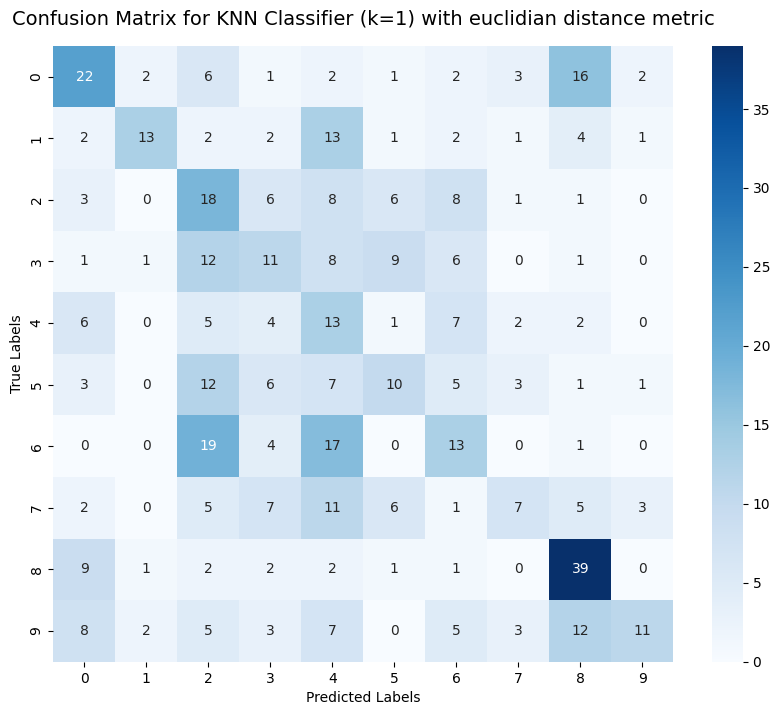

error in test dataset using manhattan distance metric (k=1): 68.40%


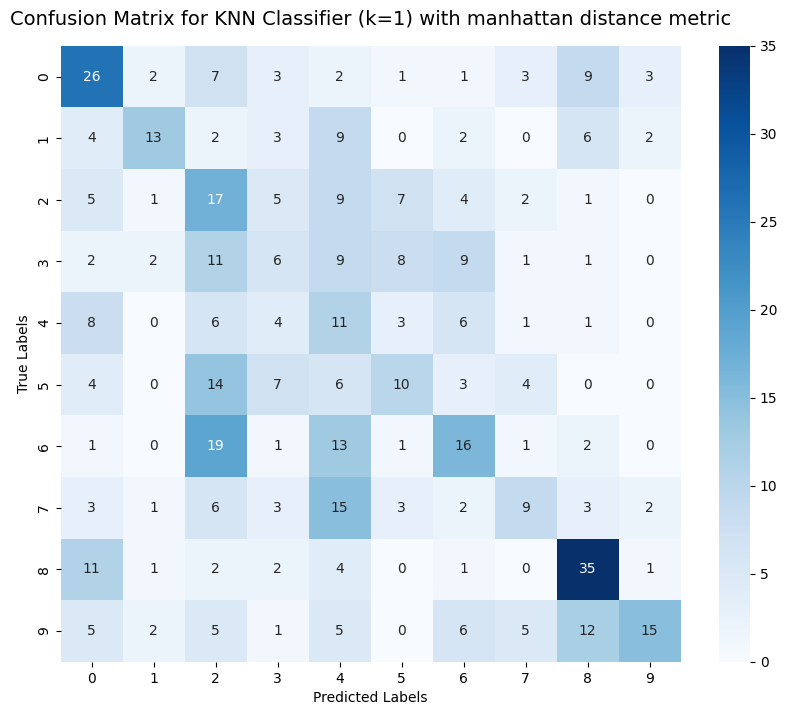

error in test dataset using chebyshev distance metric (k=1): 83.00%


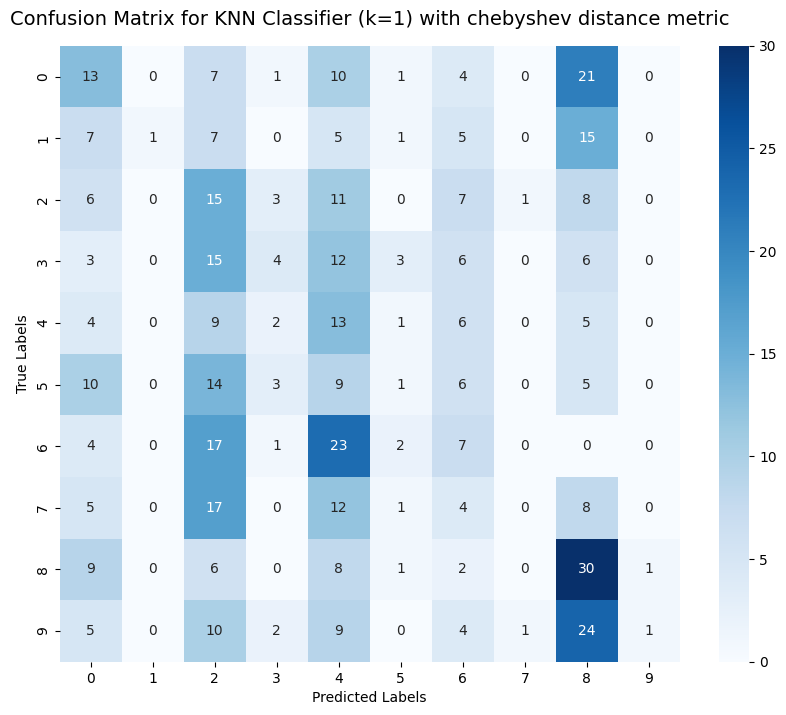

In [5]:
test_subset_size = 500 # limited subset cause it takes forever

# Test with kNN with k=1
for metric in ['euclidian', 'manhattan', 'chebyshev']:
    preds = []
    error = 0
    for i in range(test_subset_size):
        pred = knn.predict(X_train, y_train, X_test[i], k=1, distance=metric)
        preds.append(pred)
        error += 0 if pred == y_test[i] else 1
    print(f"error in test dataset using {metric} distance metric (k=1): {error/test_subset_size * 100:.2f}%")

    cm = confusion_matrix(y_test[:test_subset_size], preds)
    plt.figure(figsize=(10, 8))
    plt.title("Confusion Matrix for KNN Classifier (k=1) with " + metric + " distance metric", fontsize=14, pad=15)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

###Showing a true and a false prediction using 1NN

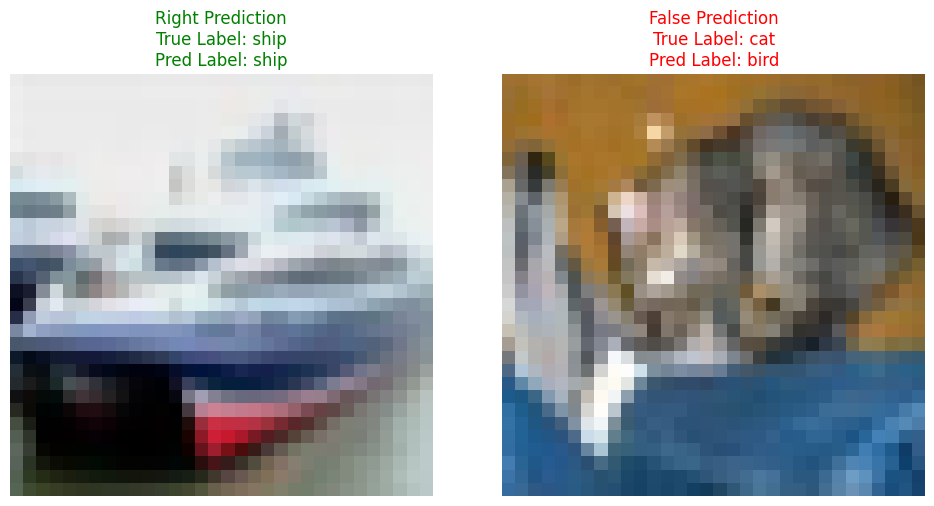

In [6]:
correct_idx = -1
incorrect_idx = -1
correct_pred = -1
incorrect_pred = -1

cifar10_classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

for i in range(len(X_test)):
    pred = knn.predict(X_train, y_train, X_test[i], k=1, distance='euclidian')

    if pred == y_test[i] and correct_idx == -1:
        correct_idx = i
        correct_pred = pred

    elif pred != y_test[i] and incorrect_idx == -1:
        incorrect_idx = i
        incorrect_pred = pred

    if correct_idx != -1 and incorrect_idx != -1:
        break

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
img_correct = X_test[correct_idx].reshape(3, 32, 32).transpose(1, 2, 0)
plt.imshow(img_correct)
plt.title(f"Right Prediction\nTrue Label: {cifar10_classes[y_test[correct_idx]]}\nPred Label: {cifar10_classes[correct_pred]}", color='green')
plt.axis('off')

plt.subplot(1, 2, 2)
img_incorrect = X_test[incorrect_idx].reshape(3, 32, 32).transpose(1, 2, 0)
plt.imshow(img_incorrect)
plt.title(f"False Prediction\nTrue Label: {cifar10_classes[y_test[incorrect_idx]]}\nPred Label: {cifar10_classes[incorrect_pred]}", color='red')
plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Evaluating KNN with $K=3$ (test subset=500 images)
I evaluate the performance of our KNN classifier on the test subset using $K=3$ to observe if a larger neighborhood improves generalization.

error in test dataset using euclidian distance metric (k=3): 68.00%


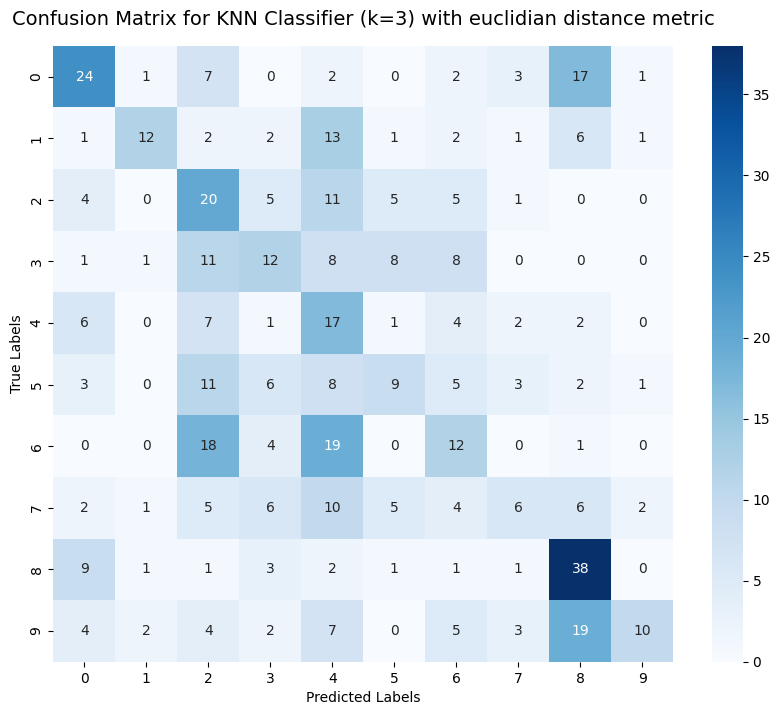

error in test dataset using manhattan distance metric (k=3): 66.80%


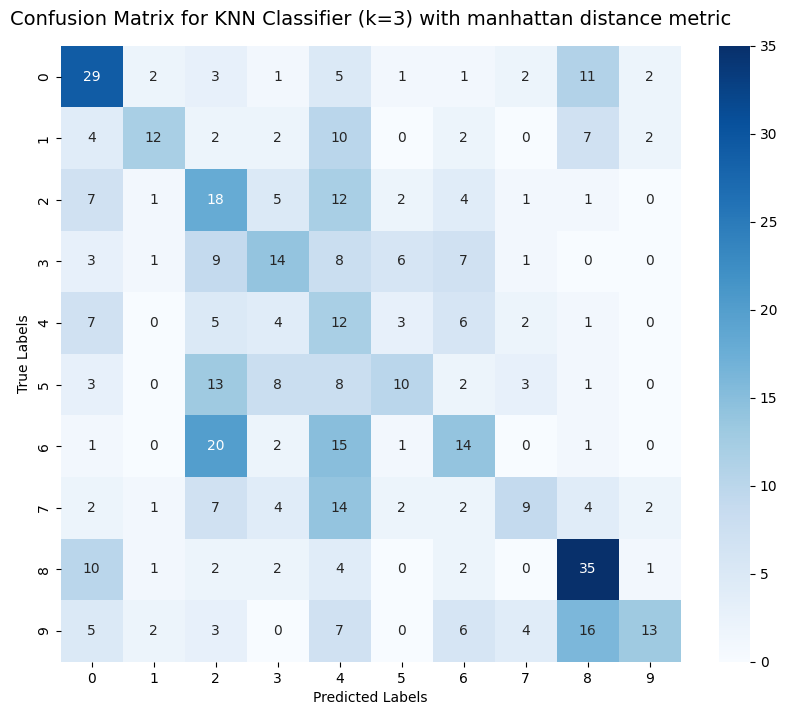

error in test dataset using chebyshev distance metric (k=3): 83.20%


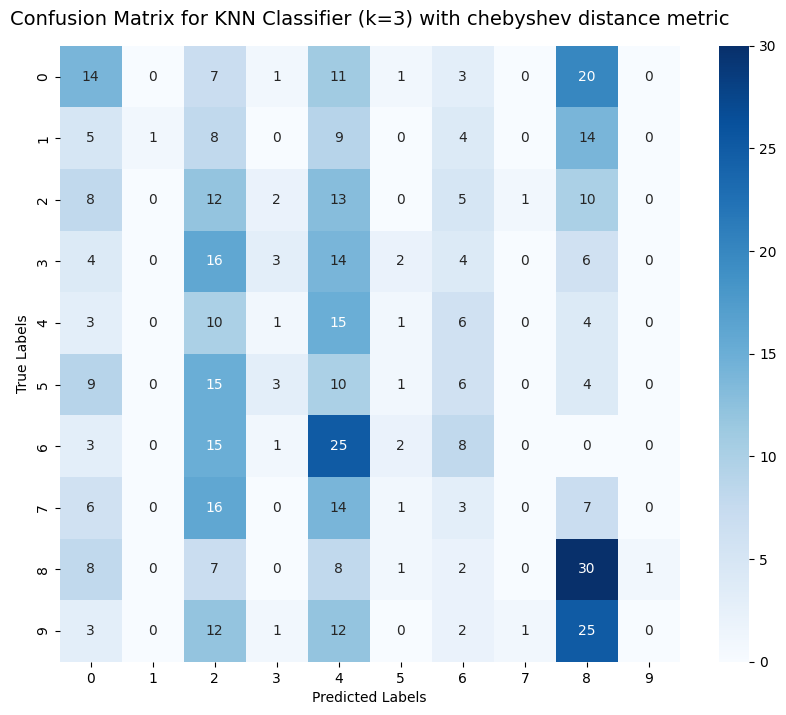

In [7]:
# Test with kNN with k=3

test_subset_size = 500 # limited subset cause it takes forever


for metric in ['euclidian', 'manhattan', 'chebyshev']:
    preds = []
    error = 0
    for i in range(test_subset_size):
        pred = knn.predict(X_train, y_train, X_test[i], k=3, distance=metric)
        preds.append(pred)
        error += 0 if pred == y_test[i] else 1
    print(f"error in test dataset using {metric} distance metric (k=3): {error/test_subset_size * 100:.2f}%")

    cm = confusion_matrix(y_test[:test_subset_size], preds)
    plt.figure(figsize=(10, 8))
    plt.title("Confusion Matrix for KNN Classifier (k=3) with " + metric + " distance metric", fontsize=14, pad=15)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

### 5. Implementing the Nearest Centroid Classifier from Scratch
I define a custom Nearest Centroid class `MyNearestCentroid` that computes the mean feature vector (centroid) for each class.

In [8]:
#Implementing Nearest Centroid from scratch

class MyNearestCentroid:

  def fit(self, x_train, y_train):

    self.classes = np.unique(y_train)
    self.centroids = np.array([
      np.mean(x_train[y_train == c], axis=0)
      for c in self.classes
      ])


  def predict(self, x, distance='euclidian'):

    if distance == 'euclidian':
      distances = np.linalg.norm(self.centroids - x, axis=1)
    elif distance == 'manhattan':
      distances = np.sum(np.abs(self.centroids - x), axis=1)
    elif distance == 'chebyshev':
      distances = np.max(np.abs(self.centroids - x), axis=1)

    idx = np.argmin(distances)
    neighbour_label = self.classes[idx]
    y_pred = neighbour_label
    return y_pred

### 6. Evaluating Nearest Centroid Classifier
I fit the Nearest Centroid model on the training dataset and evaluate its performance on the entire test dataset using Euclidean, Manhattan, and Chebyshev distances.

In [9]:
nc = MyNearestCentroid()
nc.fit(X_train, y_train)

error in test dataset using euclidian distance metric (Nearest Centroid): 72.21%


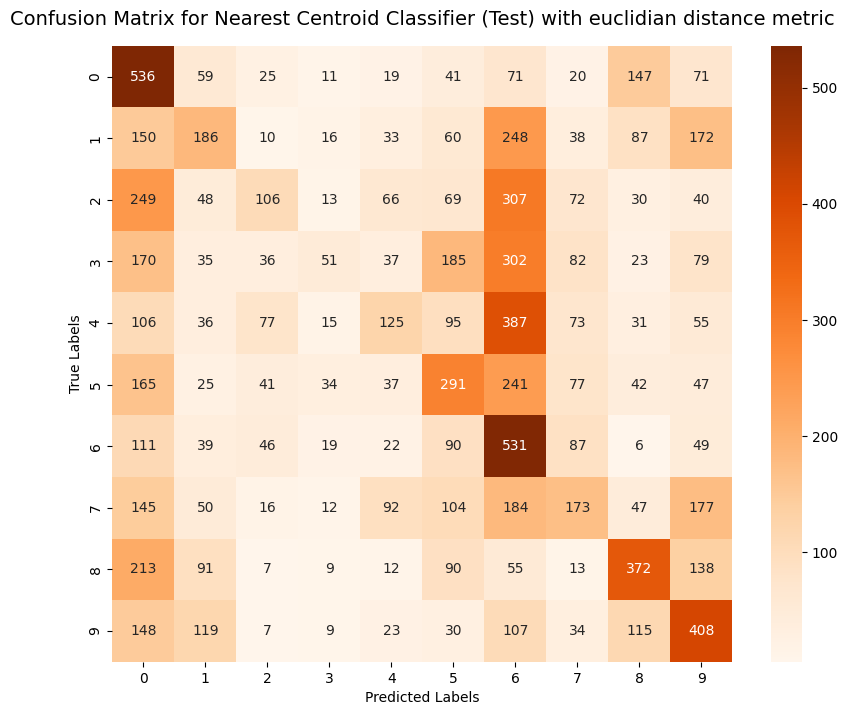

error in test dataset using manhattan distance metric (Nearest Centroid): 72.62%


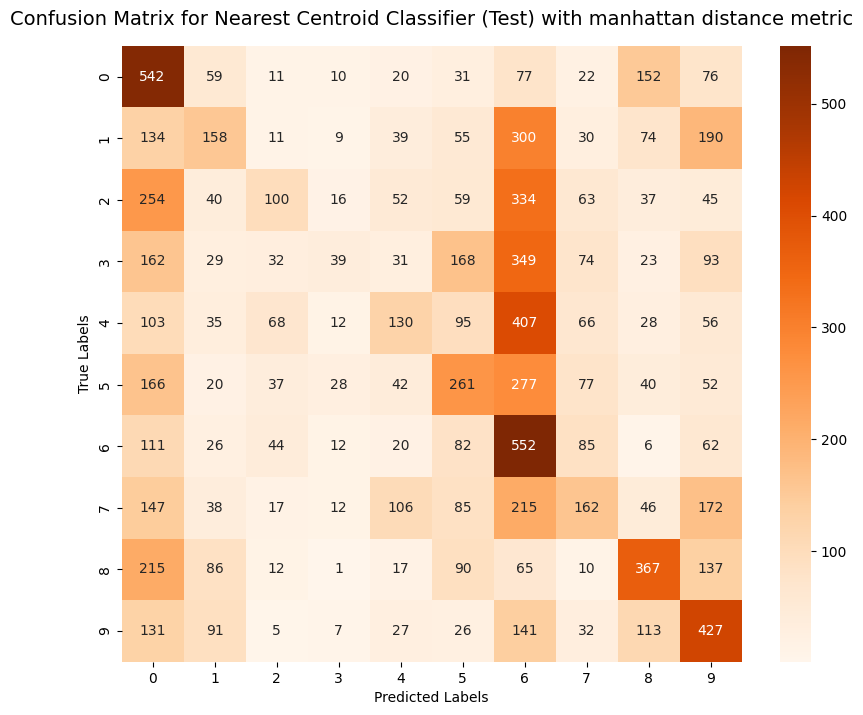

error in test dataset using chebyshev distance metric (Nearest Centroid): 78.83%


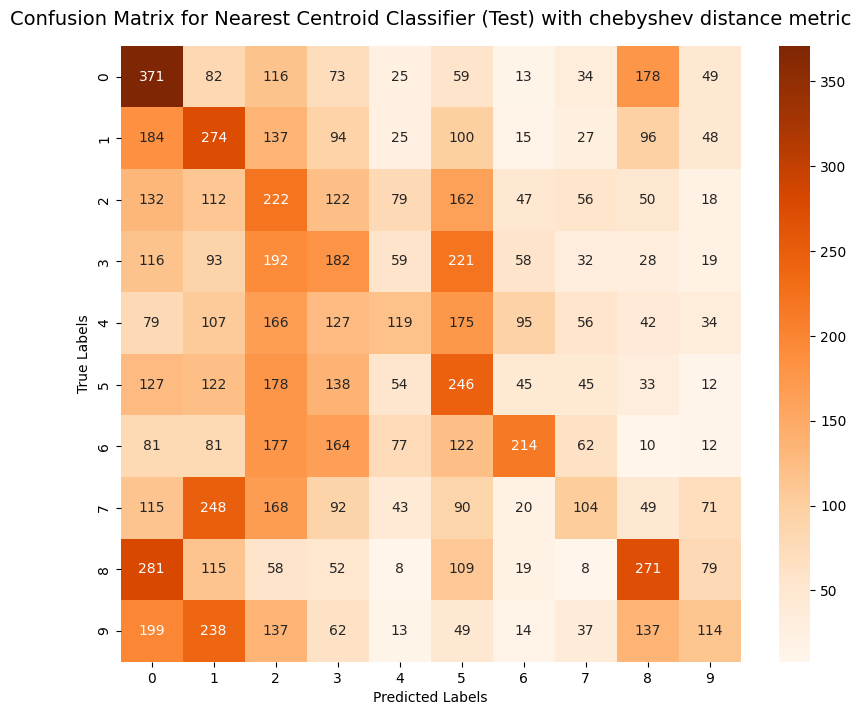

In [10]:
# Test Nearest Centroid with different distance metrics on test dataset with confusion matrices
test_subset_size = 10000

for metric in ['euclidian', 'manhattan', 'chebyshev']:
    preds = []
    error = 0
    for i in range(test_subset_size):
        pred = nc.predict(X_test[i], distance=metric)
        preds.append(pred)
        error += 0 if pred == y_test[i] else 1
    print(f"error in test dataset using {metric} distance metric (Nearest Centroid): {error/test_subset_size * 100:.2f}%")

    cm = confusion_matrix(y_test[:test_subset_size], preds)
    plt.figure(figsize=(10, 8))
    plt.title("Confusion Matrix for Nearest Centroid Classifier (Test) with " + metric + " distance metric", fontsize=14, pad=15)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

error in test dataset using euclidian distance metric (Nearest Centroid): 70.80%


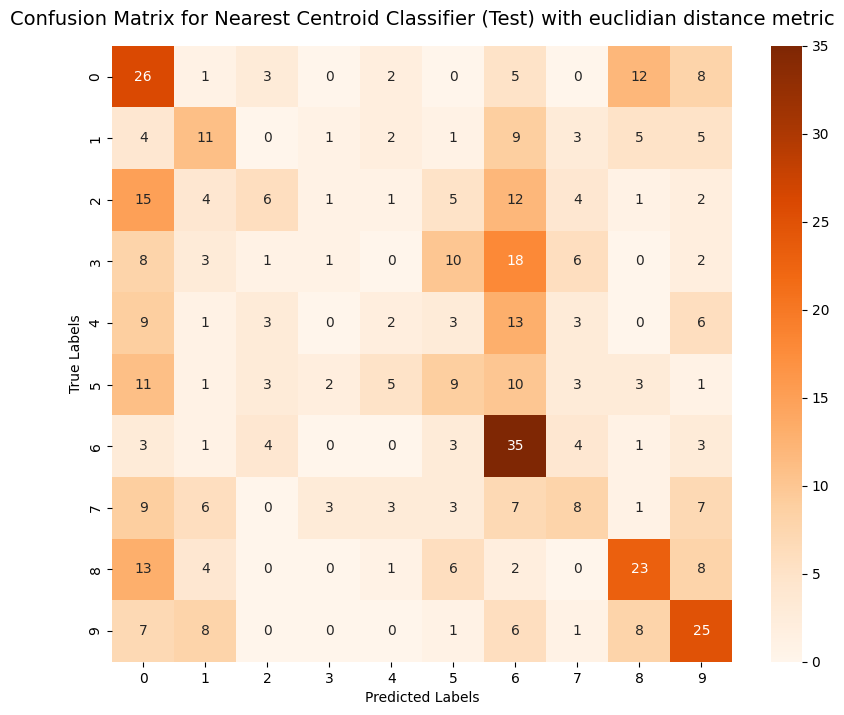

error in test dataset using manhattan distance metric (Nearest Centroid): 70.80%


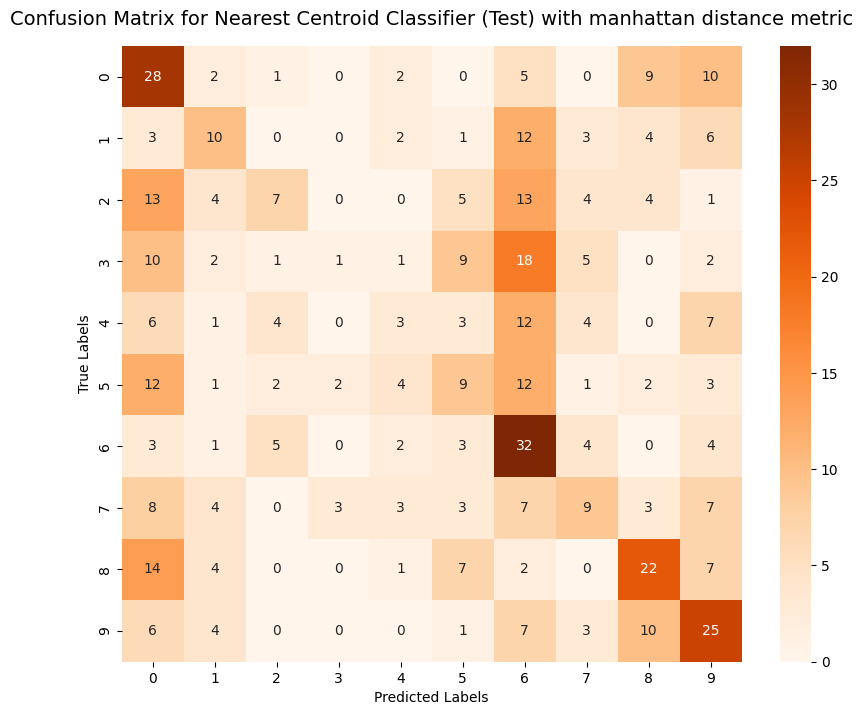

error in test dataset using chebyshev distance metric (Nearest Centroid): 81.00%


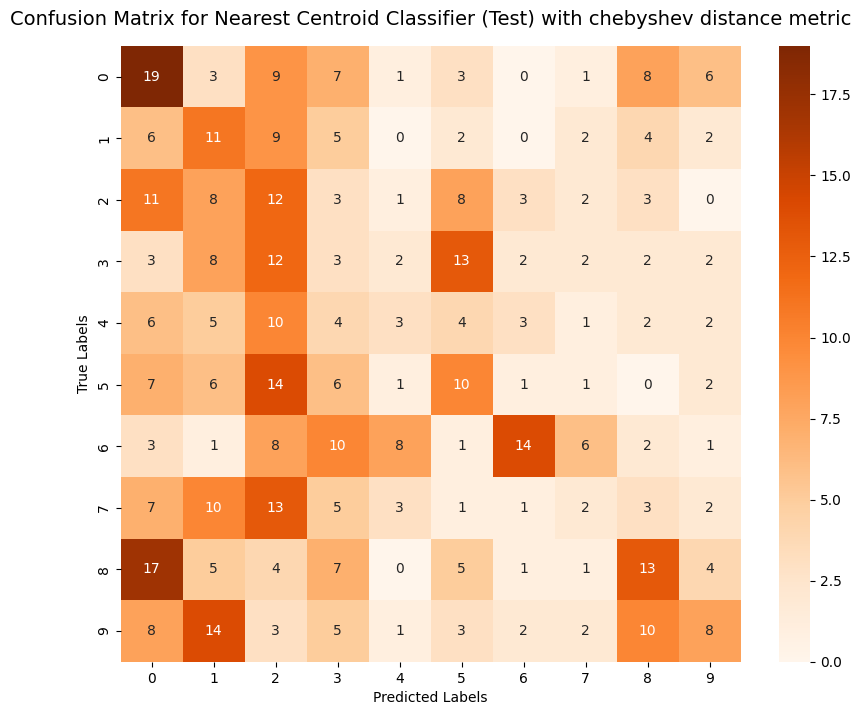

In [11]:
# Test Nearest Centroid with different distance metrics on test dataset with confusion matrices
test_subset_size = 500 #to compare with KNN

for metric in ['euclidian', 'manhattan', 'chebyshev']:
    preds = []
    error = 0
    for i in range(test_subset_size):
        pred = nc.predict(X_test[i], distance=metric)
        preds.append(pred)
        error += 0 if pred == y_test[i] else 1
    print(f"error in test dataset using {metric} distance metric (Nearest Centroid): {error/test_subset_size * 100:.2f}%")

    cm = confusion_matrix(y_test[:test_subset_size], preds)
    plt.figure(figsize=(10, 8))
    plt.title("Confusion Matrix for Nearest Centroid Classifier (Test) with " + metric + " distance metric", fontsize=14, pad=15)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

### Evaluating Nearest Centroid on the Training Dataset

Error in train dataset using euclidian distance metric (Nearest Centroid): 72.49%


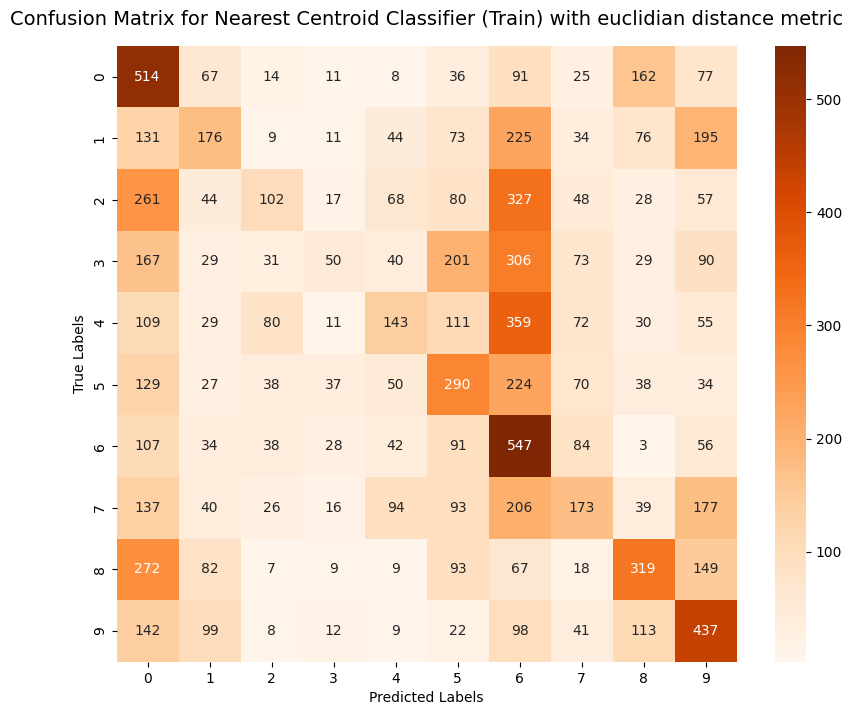

Error in train dataset using manhattan distance metric (Nearest Centroid): 72.60%


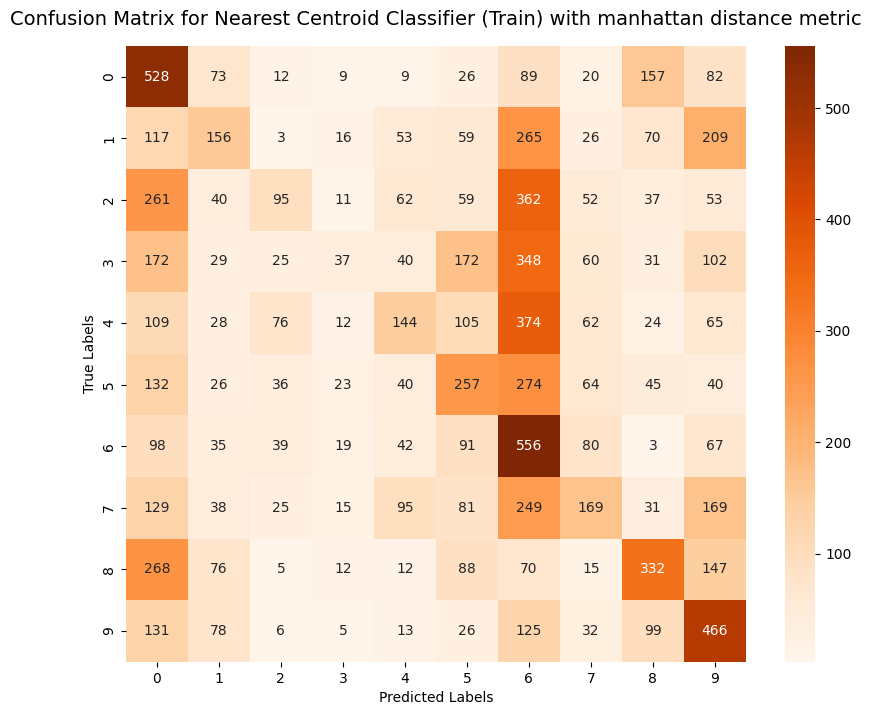

Error in train dataset using chebyshev distance metric (Nearest Centroid): 78.78%


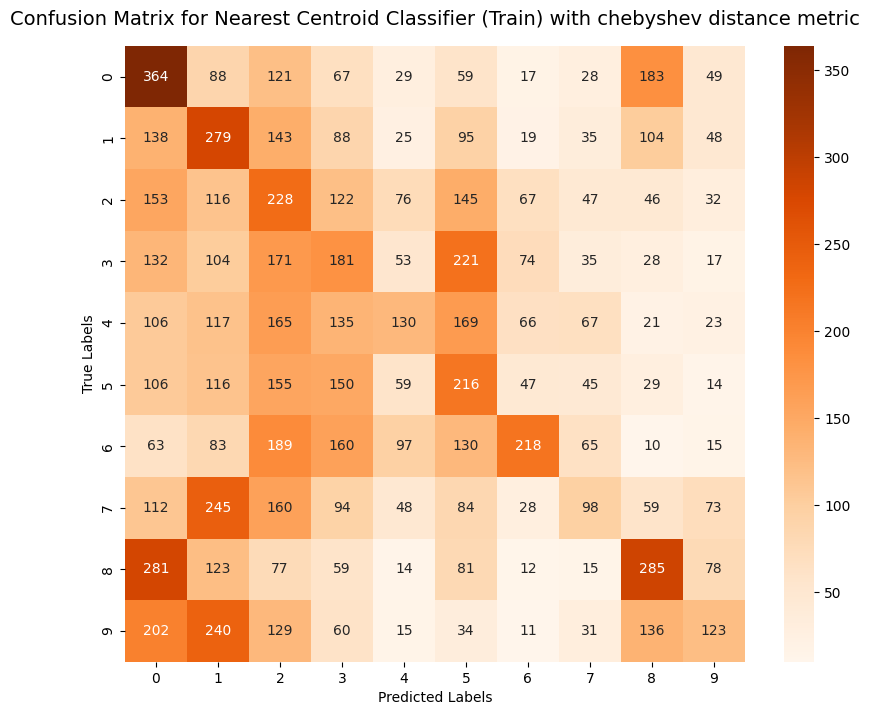

In [12]:
# Test Nearest Centroid with different distance metrics on training dataset with confusion matrices
train_subset_size_nc = 10000
nc = MyNearestCentroid()
nc.fit(X_train, y_train)

for metric in ['euclidian', 'manhattan', 'chebyshev']:
    preds = []
    error = 0
    for i in range(train_subset_size_nc):
        pred = nc.predict(X_train[i], distance=metric)
        preds.append(pred)
        error += 0 if pred == y_train[i] else 1
    print(f"Error in train dataset using {metric} distance metric (Nearest Centroid): {error/train_subset_size_nc * 100:.2f}%")

    cm = confusion_matrix(y_train[:train_subset_size_nc], preds)
    plt.figure(figsize=(10, 8))
    plt.title("Confusion Matrix for Nearest Centroid Classifier (Train) with " + metric + " distance metric", fontsize=14, pad=15)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

###Combining 1NN, 3NN and Nearest Centroid into one model with voting (Test Subset=500 images)
I evaluate the performance of that combination on the test subset to observe if voting across the 3 models improves generalization.

Error in test dataset using manhattan distance metric (Ensemble Classifier): 67.60%


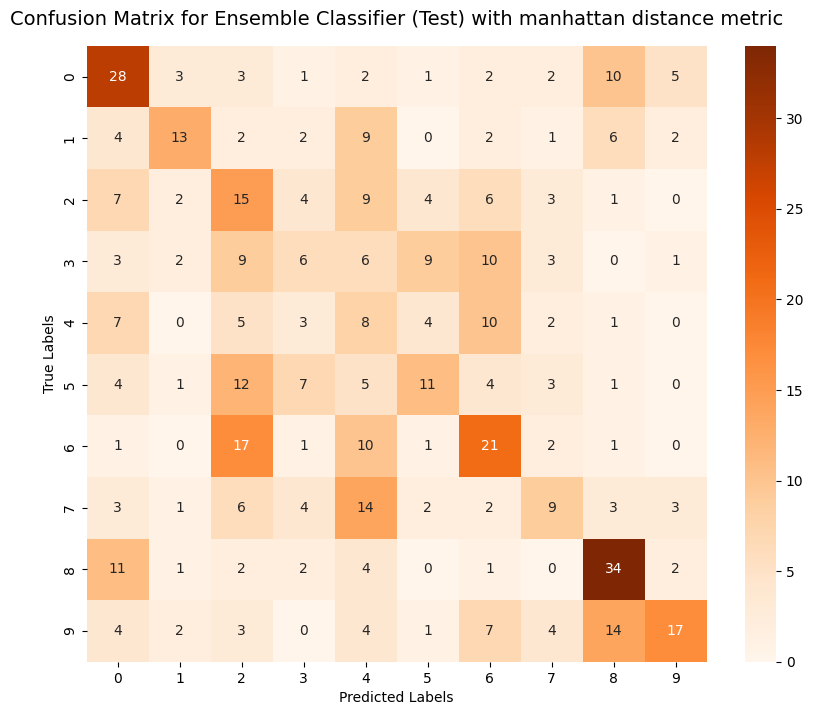

In [13]:
test_subset_size = 500
metric = 'manhattan'
preds = []
error = 0
for i in range(test_subset_size):
    pred = nc.predict(X_test[i], distance=metric)
    pred1 = knn.predict(X_train, y_train, X_test[i], k=1, distance=metric)
    pred2 = knn.predict(X_train, y_train, X_test[i], k=3, distance=metric)
    final_pred = Counter([pred, pred1, pred2]).most_common(1)[0][0]
    preds.append(final_pred)
    error += 0 if final_pred == y_test[i] else 1

print(f"Error in test dataset using {metric} distance metric (Ensemble Classifier): {error/test_subset_size * 100:.2f}%")

cm = confusion_matrix(y_test[:test_subset_size], preds)
plt.figure(figsize=(10, 8))
plt.title("Confusion Matrix for Ensemble Classifier (Test) with " + metric + " distance metric", fontsize=14, pad=15)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()